In [ ]:
from google.colab import drive
import cv2

drive.mount('/content/drive', force_remount=True)
image_path = '/content/drive/MyDrive/images/color.jpg'
image_path2 = '/content/drive/MyDrive/images/ding.png'

Mounted at /content/drive


RGB Shape: (512, 768, 3)


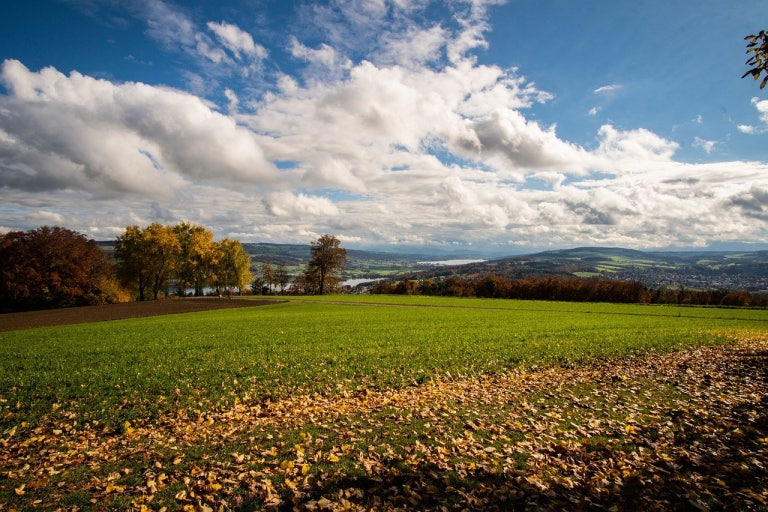

Grayscale Shape: (512, 768)


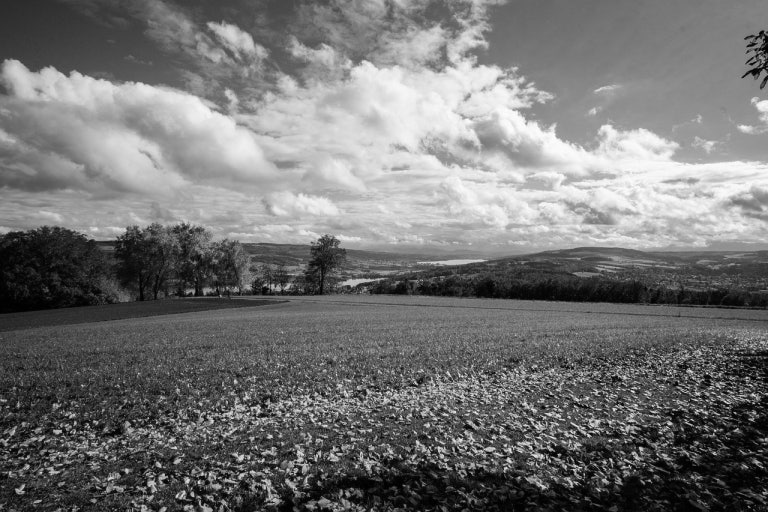

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img_rgb = cv2.imread(image_path)

if img_rgb is None:
    print(f"Error: Could not load image from {image_path}")
else:
    print("RGB Shape:", img_rgb.shape)
    cv2_imshow(img_rgb)

    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2GRAY)
    print("Grayscale Shape:", img_gray.shape)
    cv2_imshow(img_gray)

    b, g, r = cv2.split(img_rgb)


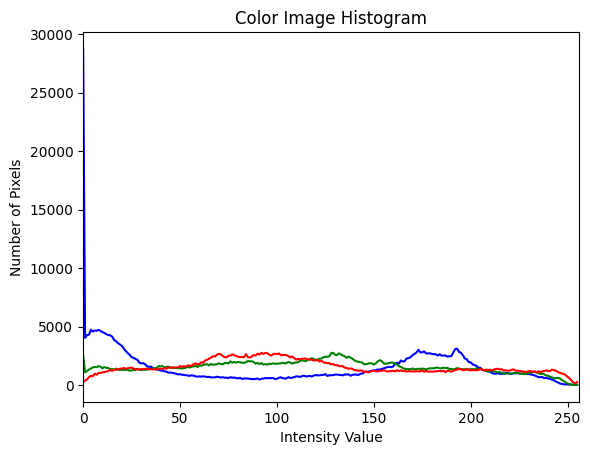

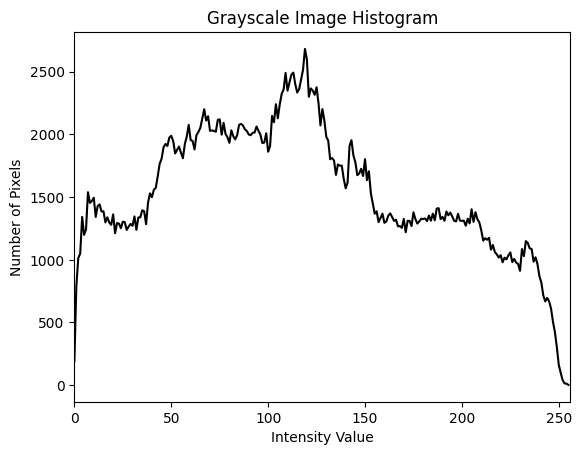

In [ ]:
import cv2
import matplotlib.pyplot as plt

plt.figure()
plt.title("Color Image Histogram")
plt.xlabel("Intensity Value")
plt.ylabel("Number of Pixels")

colors = ('b', 'g', 'r')

for i, color in enumerate(colors):
    hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
    plt.plot(hist, color=color)
    plt.xlim([0, 256])

plt.show()

hist = cv2.calcHist([img_gray], [0], None, [256], [0, 256])

plt.figure()
plt.title("Grayscale Image Histogram")
plt.xlabel("Intensity Value")
plt.ylabel("Number of Pixels")
plt.plot(hist, color='black')
plt.xlim([0, 256])
plt.show()

Original vs Equalized


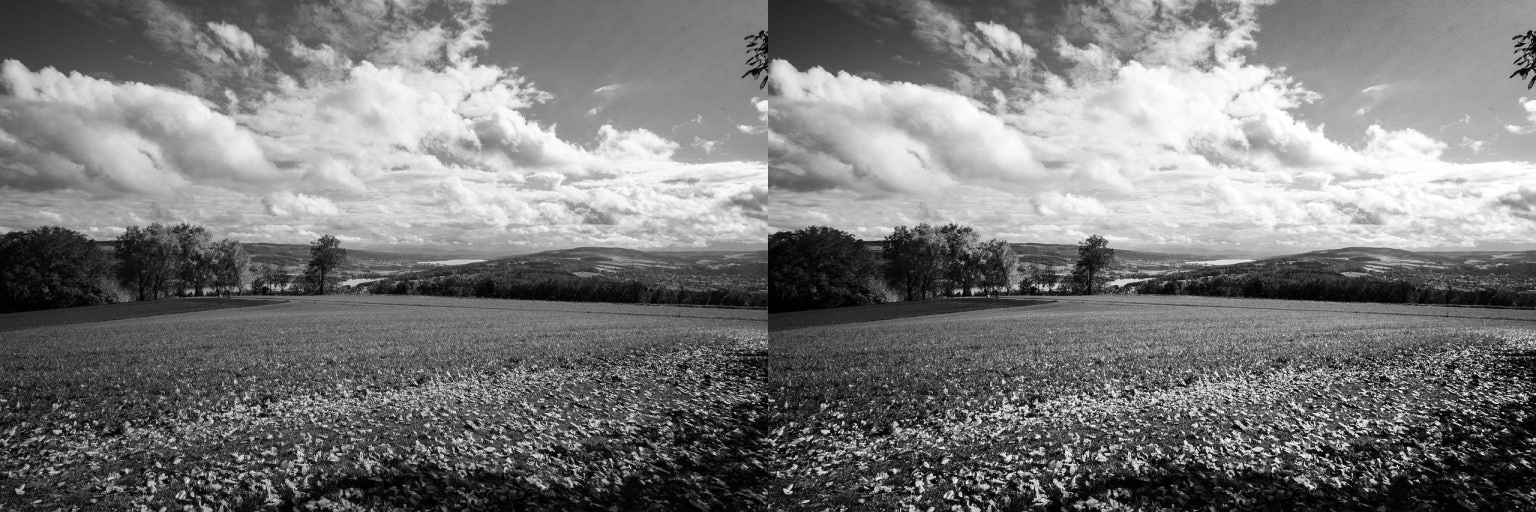

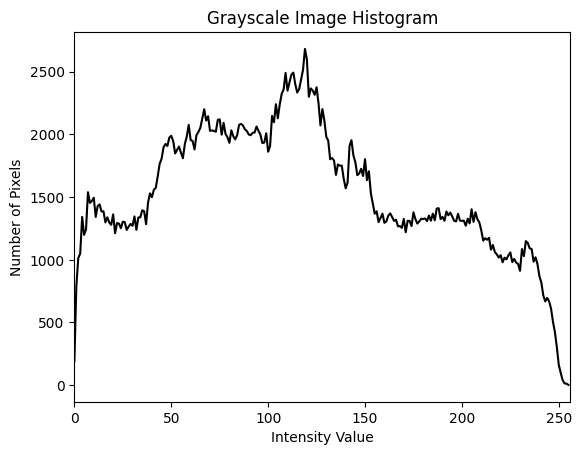

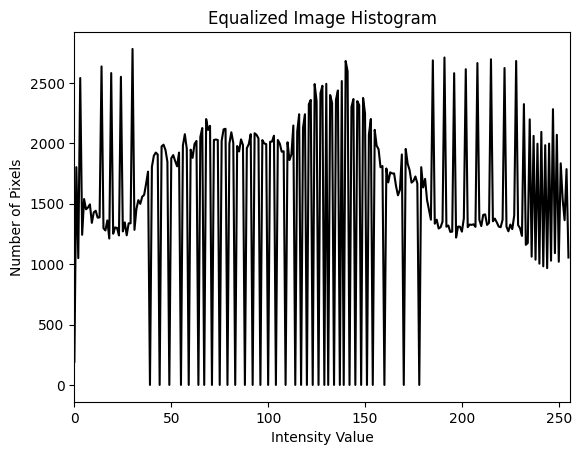

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

equalized_img = cv2.equalizeHist(img_gray)

print('Original vs Equalized')
cv2_imshow(np.hstack((img_gray, equalized_img)))

plt.show()

hist = cv2.calcHist([img_gray], [0], None, [256], [0, 256])

plt.figure()
plt.title("Grayscale Image Histogram")
plt.xlabel("Intensity Value")
plt.ylabel("Number of Pixels")
plt.plot(hist, color='black')
plt.xlim([0, 256])
plt.show()

plt.show()

hist = cv2.calcHist([equalized_img], [0], None, [256], [0, 256])

plt.figure()
plt.title("Equalized Image Histogram")
plt.xlabel("Intensity Value")
plt.ylabel("Number of Pixels")
plt.plot(hist, color='black')
plt.xlim([0, 256])
plt.show()

CLAHE Output


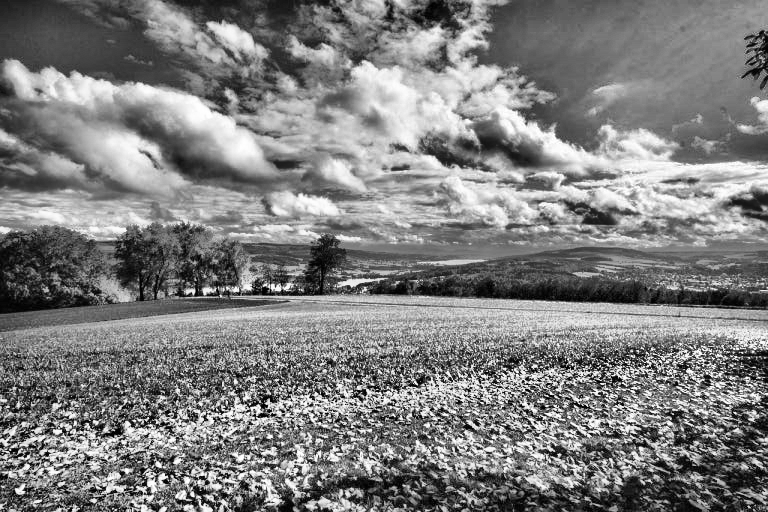

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))

clahe_img = clahe.apply(img_gray)

print('CLAHE Output')
cv2_imshow(clahe_img)

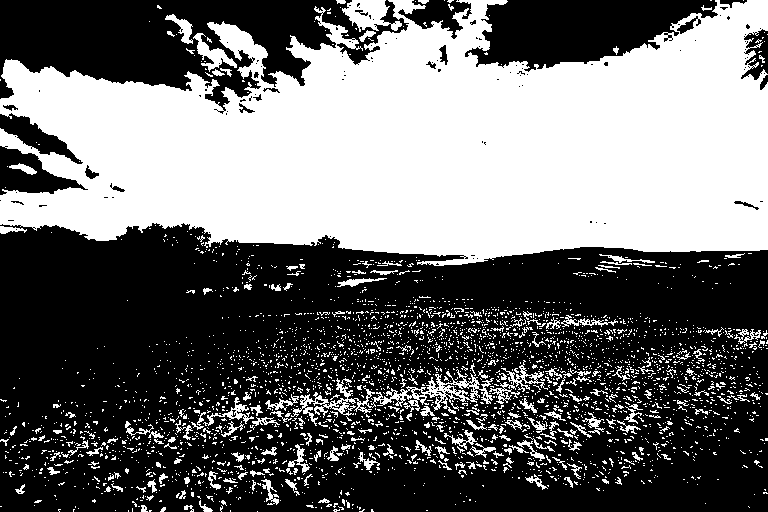

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

_, thresh_binary = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

_, thresh_otsu = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

cv2_imshow(thresh_otsu)

================================================================================
================================================================================

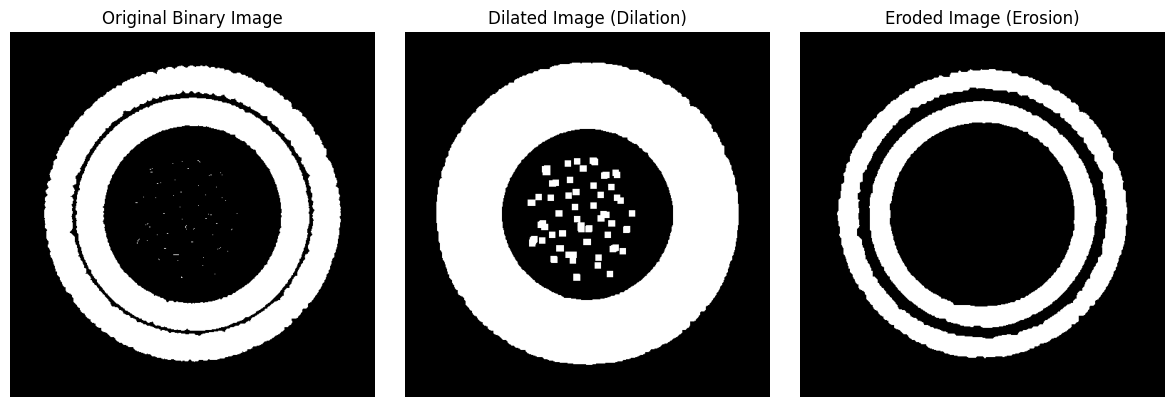

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

ding = cv2.imread(image_path2)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))

dilated_img = cv2.dilate(ding, kernel, iterations=1)
eroded_img = cv2.erode(ding, kernel, iterations=1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Original Binary Image")
plt.imshow(ding, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Dilated Image (Dilation)")
plt.imshow(dilated_img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Eroded Image (Erosion)")
plt.imshow(eroded_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

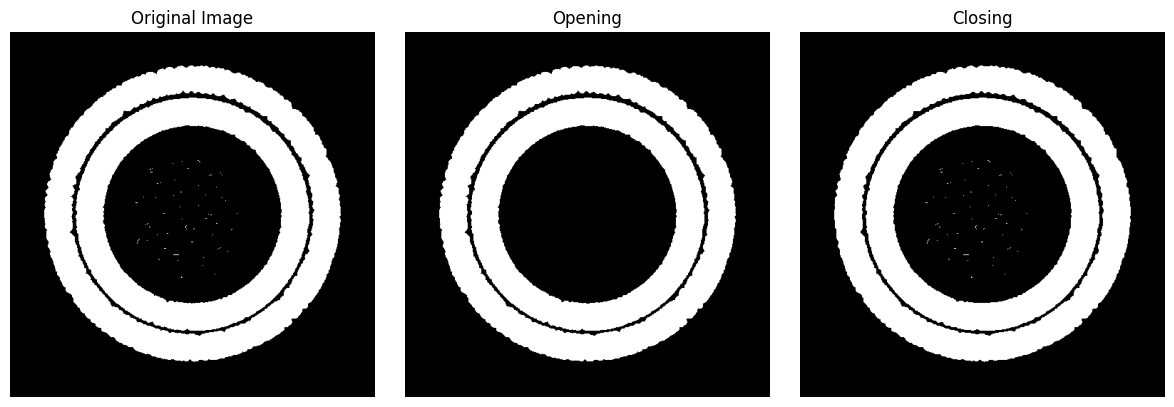

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))

opening_img = cv2.morphologyEx(ding, cv2.MORPH_OPEN, kernel)

closing_img = cv2.morphologyEx(ding, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(ding, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Opening")
plt.imshow(opening_img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Closing")
plt.imshow(closing_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import torchvision
import torchvision.transforms as transforms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

transform = transforms.Compose([transforms.ToTensor()])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

sample_size = 5000
X_train = trainset.data[:sample_size].reshape(sample_size, -1) / 255.0
y_train = np.array(trainset.targets[:sample_size])

k_values = [1, 3, 5, 7]
metrics = ['euclidean', 'manhattan'] # L2, L1 거리

results = []

for metric in metrics:
    for k in k_values:
        print(f" 실험 중 -> Metric: {metric}, k: {k}")

        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        acc_list, prec_list, rec_list, f1_list = [], [], [], []

        for train_idx, val_idx in skf.split(X_train, y_train):
            X_tr, X_val = X_train[train_idx], X_train[val_idx]
            y_tr, y_val = y_train[train_idx], y_train[val_idx]

            knn = KNeighborsClassifier(n_neighbors=k, metric=metric, n_jobs=-1)
            knn.fit(X_tr, y_tr)

            y_pred = knn.predict(X_val)

            acc = accuracy_score(y_val, y_pred)
            prec, rec, f1, _ = precision_recall_fscore_support(y_val, y_pred, average='weighted', zero_division=0)

            acc_list.append(acc)
            prec_list.append(prec)
            rec_list.append(rec)
            f1_list.append(f1)

        results.append({
            'metric': metric,
            'k': k,
            'accuracy': np.mean(acc_list),
            'precision': np.mean(prec_list),
            'recall': np.mean(rec_list),
            'f1_score': np.mean(f1_list)
        })

print("\n" + "="*60)
print(f"{'Metric':<12} | {'k':<4} | {'Accuracy':<8} | {'Precision':<9} | {'Recall':<8} | {'F1-score':<8}")
print("="*60)
for res in results:
    print(f"{res['metric']:<12} | {res['k']:<4} | {res['accuracy']:<8.4f} | {res['precision']:<9.4f} | {res['recall']:<8.4f} | {res['f1_score']:<8.4f}")
print("="*60)

 실험 중 -> Metric: euclidean, k: 1
 실험 중 -> Metric: euclidean, k: 3
 실험 중 -> Metric: euclidean, k: 5
 실험 중 -> Metric: euclidean, k: 7
 실험 중 -> Metric: manhattan, k: 1
 실험 중 -> Metric: manhattan, k: 3
 실험 중 -> Metric: manhattan, k: 5
 실험 중 -> Metric: manhattan, k: 7

Metric       | k    | Accuracy | Precision | Recall   | F1-score
euclidean    | 1    | 0.2702   | 0.3200    | 0.2702   | 0.2580  
euclidean    | 3    | 0.2538   | 0.3492    | 0.2538   | 0.2366  
euclidean    | 5    | 0.2660   | 0.3441    | 0.2660   | 0.2398  
euclidean    | 7    | 0.2738   | 0.3554    | 0.2738   | 0.2471  
manhattan    | 1    | 0.2998   | 0.3430    | 0.2998   | 0.2920  
manhattan    | 3    | 0.2898   | 0.3721    | 0.2898   | 0.2764  
manhattan    | 5    | 0.2962   | 0.3594    | 0.2962   | 0.2813  
manhattan    | 7    | 0.3036   | 0.3721    | 0.3036   | 0.2879  
